---
title: "The Prater relation: a pellet's temperature is slaved to its concentration"
description: "One linear identity fixes the temperature everywhere inside a catalyst particle from the concentration alone, whatever the kinetics and whatever the shape. Proved symbolically, confirmed numerically on two-field solves, measured against deliberately injected defects to establish what that confirmation is worth, and then broken on purpose: an external film and a transient with Le different from 1."
categories: [sec:B, struct:S3, tier:T0, data:tier6, phase:gas-solid]
date: 2026-07-31
---

# The Prater relation: a pellet's temperature is slaved to its concentration

**Catalog ID:** `B1.6` · **Structures:** `S3` (1D steady BVP) · **Tier:** T0

Inside a working catalyst particle, reactant is consumed and heat is released at
the same points, in fixed proportion. Prater showed in 1958 that this makes the
temperature field a **linear function of the concentration field**, not
approximately and not only for a sphere:

$$\lambda\,(T - T_s) \;=\; (-\Delta H)\,D_e\,(c_s - c).$$

No rate constant appears, no activation energy, no particle shape. Solve the
diffusion problem and the temperature comes free.

This page proves that, confirms it numerically in pymrm across three geometries
and three rate laws, establishes **what that numerical confirmation is and is
not sensitive to** by injecting defects on purpose, and then does the part the
1958 result could not: **finds where it stops being true, and by how much.**

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.02"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B1.6-prater-relation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Markdown, display
from pymrm import newton
from gallery_utils import Claims, load_claims
from model import (NU, FirstOrder, LangmuirHinshelwood, ZeroOrder,  # this page's model.py
                   TwoFieldPellet, violation, march, march_ivp, _rhs, peak_of, ReducedPellet,
                   collocation, shooting, shooting_at_phi, prater_beta)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.seterr(over="ignore", under="ignore")   # exp() of a depleted, ignited centre underflows
claims = Claims(PAGE.split("-")[0])
EPS = np.finfo(float).eps
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught


def ro(x):
    """A round-off-sized number, printed as this run's value."""
    return f"(here {x:.1e})"


def ladder_cell(err, n):
    """A ladder entry; within 1e3 of the round-off estimate n^2 eps its last digits
    are noise, so it is printed as this run's value."""
    return f"{ro(err):>16}" if err < 1e3 * n**2 * EPS else f"{err:16.3e}"

## Background

A porous catalyst pellet running an exothermic reaction is governed by two
balances that share one source term. Species is consumed at the local rate
$r$; heat is produced at $(-\Delta H)\,r$ at exactly the same place. The two
fields are therefore not independent, and Prater's observation is that they are
not even *approximately* independent: one determines the other exactly.

The practical consequence is the reason every non-isothermal pellet analysis
since is a **one-variable** problem. Weisz and Hicks (1962) say so in as many
words: the relation "enables us to write the reaction rate (6) in terms of one
variable instead of both, $c$ and $\Delta T$". Their whole paper, and the
[`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/) page's large effectiveness
factors and coexisting steady states, rest on it.

It also gives the single most useful number in non-isothermal catalysis for
free. Setting $c \to 0$, a fully diffusion-starved centre, bounds the internal
temperature rise:

$$(\Delta T)_{\max} = \frac{(-\Delta H)\,D_e\,c_s}{\lambda},$$

which needs no kinetics at all, only transport properties and the surface
concentration. Divided by $T_s$ it is the **Prater number** $\beta$, the
parameter labelling the curves on the Weisz-Hicks diagram.

Why does an identity deserve a gallery page? Because it is an unusually clean
example of an **internal identity the model must satisfy**, and because its
assumptions are usually left unstated. This page states them, and then breaks
each one on purpose.

## The published model

### Provenance: what was read, and what was not

**Prater's own 1958 paper is not on disk and has no open-access route.** It is
cited here as the origin of the result, from Weisz and Hicks' own reference
list, which reads:

> [11] PRATER C. D., *Chem. Engng. Sci.* 1958 **8** 284.

Everything transcribed below comes instead from **Weisz and Hicks (1962)**,
which is on disk and is also the source of the published
[`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/) page. They print the relation as
their **eq. (7)** and attribute it explicitly: Damköhler had it for the sphere,
and "this relationship was proven by PRATER [11] to apply to *any* particle
geometry."

So: **the equations on this page are Weisz and Hicks as printed; the result is
Prater's.** Nothing here is restated from memory or from a textbook. The scan's
text layer is badly mangled (it renders eq. (7) as `AT = T - To = - F` /
`[grad ~1,~~`), so every symbol below was read off a 600 dpi render of journal
page 266 (`pdftoppm -r 600 -f 2 -l 2 -png`).

### The equations, as printed

Weisz and Hicks define $K$ = thermal conductivity, $H$ = molar heat of reaction,
and $\mathrm{d}n/\mathrm{d}t$ = "the actual per unit volume reaction rate in a
volume element". Their transport equations are

$$D\nabla^2 c - \frac{\mathrm{d}n}{\mathrm{d}t} = 0 \tag{4}$$

$$K\nabla^2 T - H\frac{\mathrm{d}n}{\mathrm{d}t} = 0 \tag{5}$$

and the relation itself, printed exactly as

$$\Delta T = T - T_0 = -\frac{HD}{K}\,(c_0 - c), \tag{7}$$

"with $T_0$ and $c_0$ being the boundary values". The dimensionless groups
follow as

$$\gamma = \frac{Q}{RT_0}, \qquad
\beta = \frac{c_0 H D}{K T_0} = \left(\frac{\Delta T}{T_0}\right)_{\!\max},
\qquad y = \frac{c}{c_0}. \tag{8}$$

### One sign has to be resolved before anything is built

Eq. (7) is *exactly* what eqs. (4) and (5) give; the check below confirms it
symbolically. But eq. (7) at $c \to 0$ gives
$(\Delta T/T_0)_{\max} = -c_0HD/(KT_0)$, which is the **negative** of the middle
member of eq. (8). The two printed expressions for $\beta$ therefore disagree in
sign, and the disagreement is not cosmetic: it decides whether an exothermic
pellet is hotter or colder inside.

Three pieces of the paper's own content settle it, and all three agree:

1. Eq. (8)'s rate, $\mathrm{d}n/\mathrm{d}t = k_0c_0\,y\exp\{\gamma\beta(1-y)/[1+\beta(1-y)]\}$,
   is eq. (6) with $\Delta T/T_0$ replaced by $\beta(1-y)$. That substitution
   requires $\beta = +(\Delta T/T_0)_{\max}$, the right-hand member.
2. The paper sweeps "$\beta$ in the range from 0 to $+0.8$ (exothermic
   reaction) and 0 to $-0.8$ (endothermic)".
3. Its central result is $\eta \gg 1$, which needs the exponent to be
   *positive* where the pellet is depleted, i.e. hotter inside.

So $H$ in eqs. (5) and (7) is the molar **enthalpy** of reaction, negative when
heat is released, and $\beta$ is defined positive for an exothermic reaction. In
modern notation, with $(-\Delta H) > 0$ exothermic, $\lambda$ the effective
conductivity and $D_e$ the effective diffusivity, the two printed statements
become unambiguous and are what this page uses throughout:

$$\boxed{\;\lambda\,(T - T_s) = (-\Delta H)\,D_e\,(c_s - c)\;}
\qquad
\beta = \frac{(-\Delta H)\,D_e\,c_s}{\lambda\,T_s}
= \left(\frac{\Delta T}{T_s}\right)_{\!\max}.$$

This is the same $\beta$ that labels the curves on
[`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/); the cross-check below confirms the
two pages use it identically.

## Parameters and assumptions

The relation holds under five assumptions, and this page tests each of them:

| # | assumption | what happens without it |
|---|---|---|
| 1 | steady state | fails; quantified below, exactly recovered when $Le = 1$ |
| 2 | one reaction, so both balances share one $r$ | fails (not tested here) |
| 3 | constant $D_e$ and $\lambda$ | the linear relation between $T$ and $c$ fails. If $D_e = D_e(c)$ and $\lambda = \lambda(T)$, the Kirchhoff potentials $\Phi_c = \int D_e\,\mathrm{d}c$ and $\Phi_T = \int \lambda\,\mathrm{d}T$ satisfy $\nabla^2[\Phi_T + (-\Delta H)\Phi_c] = 0$, so what survives is a linear relation between the *potentials*; between $T$ and $c$ it becomes nonlinear (not tested here) |
| 4 | the **same** boundary condition type for both fields | fails; quantified below |
| 5 | nothing about the kinetics, and nothing about the geometry | *these are the point: they are not assumptions* |

Everything on this page is dimensionless. With $u$ the position scaled on the
characteristic length $L$, $y = c/c_s$ and $\theta = T/T_s$, the steady pellet is

$$\nabla^2 y = \phi^2\,\mathcal{R}(y,\theta), \qquad
\nabla^2 \theta = -\beta\,\phi^2\,\mathcal{R}(y,\theta),$$

with $\phi = L\sqrt{k_s/D_e}$ the Thiele modulus, $\gamma = E/(R_gT_s)$ the
Arrhenius number, $\beta$ the Prater number, and $\nabla^2$ carrying the
geometry index $\nu = 0, 1, 2$ for slab, cylinder and sphere. **The two
equations are solved as two coupled fields and the Prater relation is never
substituted anywhere in the solver**; that is the whole design of the page.

Three rate laws are used, all pointwise in $(y,\theta)$:

$$\mathcal{R}_{1} = y\,e^{\gamma(1-1/\theta)}, \qquad
\mathcal{R}_{\mathrm{LH}} = \frac{y\,e^{\gamma(1-1/\theta)}}{\left[1 + K(\theta)\,y\right]^2},
\quad K(\theta) = K_s e^{\gamma_a(1/\theta-1)}, \qquad
\mathcal{R}_{0} = e^{\gamma(1-1/\theta)} .$$

$\mathcal{R}_1$ is Weisz and Hicks' own kinetics written in $\theta$; the other
two are chosen because the identity claims they cannot matter. The
Langmuir-Hinshelwood form carries a *second* temperature dependence, in the
adsorption constant ($\gamma_a = 8$, $K_s = 3$), which is the sharpest
available test of that claim.

In [3]:
# The sweep: every case is solved as two fields on N_SWEEP cells.
KIN = {"first order": FirstOrder, "Langmuir-Hinshelwood": LangmuirHinshelwood,
       "zero order": ZeroOrder}
SWEEP = [("first order",          (0.3, 1.0, 2.0), (-0.4, -0.1, 0.1, 0.3, 0.6)),
         ("Langmuir-Hinshelwood", (0.3, 1.0, 2.0), (-0.4, -0.1, 0.1, 0.3, 0.6)),
         ("zero order",           (0.2, 0.4),      (-0.4, -0.1, 0.1))]   # (kinetics, phi, beta)
GAMMAS = (10.0, 20.0, 30.0)        # Arrhenius numbers [-]
N_SWEEP = 200                      # cells [-]
CASES = [(kin, geom, gamma, beta, phi) for kin, phis, betas in SWEEP for geom in NU
         for gamma in GAMMAS for beta in betas for phi in phis]
print(f"{len(CASES)} cases: 3 geometries, 3 rate laws, {len(GAMMAS)} Arrhenius numbers, "
      f"Prater numbers from {min(min(b) for _, _, b in SWEEP)} to {max(max(b) for _, _, b in SWEEP)}")

324 cases: 3 geometries, 3 rate laws, 3 Arrhenius numbers, Prater numbers from -0.4 to 0.6


## The data

**There is none, and there does not need to be: provenance tier 6.**

This page compares a model with an identity, not with a measurement. Weisz and
Hicks (1962) report no experimental data at all (the same finding recorded for
`B1.1`), and Prater (1958) is a theoretical note. The validation route used
here, *an internal identity the model must satisfy*, needs no dataset and no
digitised figure. Nothing on this page is digitised and no CSV is shipped.

**This is a proof plus numerical confirmation. It is not experimental
validation, and the two must not be blurred.** A pellet whose measured centre
temperature matched $\beta T_s(1-y_c)$ would be validation; nothing below is.

## PyMRM implementation

`TwoFieldPellet` in `model.py` discretises the two balances as an honest coupled
system and lets the solver find both fields; nowhere does it use
$\theta = 1 + \beta(1-y)$.

- **One state, two fields, spatial axis first.** `BlockLayout.from_fields(["y",
  "theta"], (n,))` gives the `(n, 2)` state, `y` in column 0 and `theta` in
  column 1; one `construct_grad` and one `construct_div` on that shape serve
  both fields. The operator `div grad` is assembled once per pellet.
- **Boundary conditions use the OUTWARD normal**, one column per field. At the
  centre the outward normal points inward, so symmetry is $\partial y/\partial n
  = 0$; at the surface it points outward, so a film reads
  $\partial y/\partial n + Bi\,y = Bi$ with the same sign for both fields. Each
  `bc` in `model.py` carries its physical equation in a comment.
- **The exact Jacobian.** The rate couples $y$ and $\theta$ at the same point
  only, so its Jacobian is one 2 x 2 block per cell,
  `construct_coefficient_matrix(dsrc, shape=((n, 2, 1), (n, 1, 2)))` with
  `dsrc[i, a, b]` the derivative of source `a` with respect to field `b`,
  added to the constant `div grad`.
- **The solve.** `pseudo_transient` from the surface state $y = \theta = 1$:
  a steady Newton solve first, which is all most cases need, and where that
  fails, implicit pseudo-time steps with equal capacities for both fields (a
  start-up at $Le = 1$ in those cases), finished by a steady `newton` with
  `tol=1e-12` and `stagnation=True`. The solve raises unless that Newton solve
  reports success. A march needs no path in $\beta$, so it cannot stop at a
  fold on the way to the case it solves. **Where several steady states exist,
  the solve lands on the least-ignited one, the state a start-up from surface
  conditions reaches**; the cell after the cross-page checks counts those cases
  and checks one of them against a resolved $Le = 1$ start-up.
  `bounds` keeps $\theta$ above 0.2 during the iteration. That floor is a
  numerical safeguard: the Arrhenius factors stay finite down to about 0.012,
  and by the Prater identity every root has $\theta \ge 1 + \beta_{\min}$
  (printed under the sweep), so the floor cannot bind at a root; the solve
  checks that no converged state comes near it.

Surface values and the surface flux are read with `compute_boundary_values`,
so the effectiveness factor is the flux the operator transports.

In [4]:
_pel = TwoFieldPellet("sphere", 4)
print("state shape", _pel.shape, "fields", list(_pel.layout.shapes), "; div grad nonzeros:",
      _pel.lap.nnz, "(two tridiagonal blocks, interleaved)")

state shape (4, 2) fields ['y', 'theta'] ; div grad nonzeros: 20 (two tridiagonal blocks, interleaved)


## Results

### 1. The proof, in one line

Multiply the species balance by $\beta$ and add the energy balance. The rate
cancels *identically*, whatever function it is, leaving

$$\nabla^2\!\left(\theta + \beta y\right) = 0 .$$

So $w = \theta + \beta y$ is **harmonic**. It equals $1+\beta$ on the whole
boundary, because both fields are Dirichlet there with the same reference
values. A harmonic function equal to a constant on the boundary of a bounded
domain equals that constant everywhere (uniqueness of the Dirichlet problem, or
the maximum principle), and that argument uses nothing about the shape of the
domain, which is exactly Prater's claim about "any particle geometry". Hence
$\theta + \beta y \equiv 1 + \beta$, which is the relation.

The cell below does this symbolically for a general geometry index $\nu$ and a
completely unspecified rate function.

In [5]:
u = sp.Symbol("u", positive=True)
nu_s, beta_s, phi_s, gamma_s = sp.symbols("nu beta phi gamma", real=True)
y_f, th_f, w_f = sp.Function("y"), sp.Function("theta"), sp.Function("w")
R_f = sp.Function("R")            # completely arbitrary kinetics


def laplacian(f):
    """(1/u^nu) d/du (u^nu df/du): slab, cylinder, sphere and everything between."""
    return sp.diff(f, u, 2) + nu_s * sp.diff(f, u) / u


def rate_cancels(species_sign=-1):
    """Whether energy + beta*species - laplacian(theta + beta*y) vanishes for any R.
    ``species_sign=+1`` writes the species balance with the source's sign flipped."""
    rate_sym = R_f(y_f(u), th_f(u))
    res_species = laplacian(y_f(u)) + species_sign * phi_s**2 * rate_sym   # = 0
    res_energy = laplacian(th_f(u)) + beta_s * phi_s**2 * rate_sym        # = 0
    combo = sp.simplify(res_energy + beta_s * res_species - laplacian(th_f(u) + beta_s * y_f(u)))
    return combo == 0, combo


IDENTITY_OK, _combo = rate_cancels()
print("energy + beta*species - laplacian(theta + beta*y)  =", _combo)
claims.exact("identity_symbolic", bool(IDENTITY_OK))

# a harmonic function with a symmetric centre is constant. dsolve's general form
# degenerates at nu = 1 (the cylinder), where the second solution is log u.
gen = sp.dsolve(sp.Eq(laplacian(w_f(u)), 0), w_f(u)).rhs
print("general solution of laplacian(w) = 0, generic nu :", sp.simplify(gen))
for nu_val in (0, 1, 2):
    g_i = sp.dsolve(sp.Eq(laplacian(w_f(u)).subs(nu_s, nu_val), 0), w_f(u)).rhs
    print(f"   nu = {nu_val} ({['slab', 'cylinder', 'sphere'][nu_val]:8s})"
          f"                       : {sp.simplify(g_i)}")
print("The second solution is singular at the centre for nu >= 1 (log u at nu = 1,")
print("u^(1-nu) for nu > 1) and has non-zero slope there for nu = 0, so regularity")
print("plus dw/du(0) = 0 leaves only the constant: theta + beta*y = 1 + beta")
print("everywhere, for any R and any nu.")

energy + beta*species - laplacian(theta + beta*y)  = 0


general solution of laplacian(w) = 0, generic nu : C1 + C2*u**(1 - nu)
   nu = 0 (slab    )                       : C1 + C2*u
   nu = 1 (cylinder)                       : C1 + C2*log(u)
   nu = 2 (sphere  )                       : C1 + C2/u
The second solution is singular at the centre for nu >= 1 (log u at nu = 1,
u^(1-nu) for nu > 1) and has non-zero slope there for nu = 0, so regularity
plus dw/du(0) = 0 leaves only the constant: theta + beta*y = 1 + beta
everywhere, for any R and any nu.


### 2. Checking the transcription before building on it

A reading off a page image is a transcription and needs checking like any other.
Three checks, all using only the paper's own printed content.

In [6]:
D, K, H, c0, T0, c, T, lap_c, lap_T, dndt = sp.symbols("D K H c_0 T_0 c T L_c L_T n", real=True)
y_s = sp.Symbol("y", positive=True)
x_s = sp.Symbol("x", real=True)


def transcription(h_sign=1, eq8_denominator_sign=1):
    """Checks A (eq. 7 from eqs. 4-5) and C (which reading of beta reproduces
    eq. 8's exponent). The arguments flip one printed sign each (defects)."""
    eq4 = sp.Eq(D * lap_c - dndt, 0)                       # printed eq. (4)
    eq5 = sp.Eq(K * lap_T - h_sign * H * dndt, 0)          # printed eq. (5)
    sol45 = sp.solve([eq4, eq5], [dndt, lap_T], dict=True)[0]
    a_elim = sp.simplify(sol45[lap_T] - H * D * lap_c / K) == 0
    dT_printed = -H * D / K * (c0 - c)                     # printed eq. (7)
    a_int = sp.simplify(H * D * (c - c0) / K - dT_printed) == 0
    exponent_eq6 = gamma_s * x_s / (1 + x_s)               # eq. (6), x = dT/T0
    exponent_eq8 = (gamma_s * beta_s * (1 - y_s)
                    / (1 + eq8_denominator_sign * beta_s * (1 - y_s)))   # printed eq. (8)
    closes = {name: sp.simplify(exponent_eq6.subs(x_s, sign * beta_s * (1 - y_s))
                                - exponent_eq8) == 0
              for name, sign in (("+", 1), ("-", -1))}
    reading = [k for k, ok in closes.items() if ok]
    return bool(a_elim and a_int), (reading[0] if len(reading) == 1 else "none"), closes, dT_printed


EQ7_OK, READING, CLOSES, dT_printed = transcription()
print("A. eq. (7) is the integral of eqs. (4), (5) with matched Dirichlet data :", EQ7_OK)
print(f"B. (dT/T0)_max from eq. (7): {sp.simplify(dT_printed.subs(c, 0) / T0)};"
      f"  beta as printed in eq. (8): {c0 * H * D / (K * T0)}")
print("   the two printed forms differ by a sign; check C selects the reading")
for k, ok in CLOSES.items():
    print(f"C. beta = {k}(dT/T0)_max reproduces eq. (8)'s exponent : {ok}")
print(f"\nOnly beta = {READING}(dT/T0)_max closes, which agrees with the paper sweeping beta")
print("from 0 to +0.8 for EXOTHERMIC reactions and with its central result eta >> 1.")
claims.exact("eq7_from_eqs4_5", EQ7_OK)
claims.exact("eq8_beta_reading", READING)

A. eq. (7) is the integral of eqs. (4), (5) with matched Dirichlet data : True
B. (dT/T0)_max from eq. (7): -D*H*c_0/(K*T_0);  beta as printed in eq. (8): D*H*c_0/(K*T_0)
   the two printed forms differ by a sign; check C selects the reading
C. beta = +(dT/T0)_max reproduces eq. (8)'s exponent : True
C. beta = -(dT/T0)_max reproduces eq. (8)'s exponent : False

Only beta = +(dT/T0)_max closes, which agrees with the paper sweeping beta
from 0 to +0.8 for EXOTHERMIC reactions and with its central result eta >> 1.


### 3. What the Prater number is worth in kelvin

$\beta$ is a transport group, so the maximum internal temperature rise can be
written down before any kinetics is known. The numbers below are **an
order-of-magnitude illustration with round values, taken from no source**; they
show the size of the effect, not any real catalyst.

In [7]:
BETA_ROWS = [(-100.0, 1e-6, 20.0, 0.3, 600.0),     # (dH kJ/mol, D_e m2/s, c_s mol/m3,
             (-100.0, 1e-6, 200.0, 0.3, 600.0),    #  lam W/m/K, T_s K)
             (-800.0, 5e-6, 40.0, 0.5, 700.0),
             (+180.0, 1e-6, 100.0, 0.3, 900.0)]


def beta_table(dh_scale=1.0):
    """beta and dT_max per row; ``dh_scale=1e3`` hands dH over in J/mol (a defect)."""
    return [(prater_beta(dh * dh_scale, de, cs, lam, ts),
             prater_beta(dh * dh_scale, de, cs, lam, ts) * ts) for dh, de, cs, lam, ts in BETA_ROWS]


print(f"{'(-dH) kJ/mol':>13} {'D_e m2/s':>10} {'c_s mol/m3':>11} "
      f"{'lam W/m/K':>10} {'T_s K':>7} {'beta':>9} {'dT_max K':>9}")
for (dh, de, cs, lam, ts), (b, dt) in zip(BETA_ROWS, beta_table()):
    print(f"{-dh:13.0f} {de:10.1e} {cs:11.0f} {lam:10.2f} {ts:7.0f} {b:9.4f} {dt:9.1f}")
claims.value("beta_table_max_dT_K", max(dt for _, dt in beta_table()), rtol=1e-9, unit="K")
display(Markdown(
    f"A strongly exothermic oxidation can hold {claims['beta_table_max_dT_K']:.0f} K inside a "
    "millimetre of catalyst; the last row is endothermic, so $\\beta < 0$."))

 (-dH) kJ/mol   D_e m2/s  c_s mol/m3  lam W/m/K   T_s K      beta  dT_max K
          100    1.0e-06          20       0.30     600    0.0111       6.7
          100    1.0e-06         200       0.30     600    0.1111      66.7
          800    5.0e-06          40       0.50     700    0.4571     320.0
         -180    1.0e-06         100       0.30     900   -0.0667     -60.0


A strongly exothermic oxidation can hold 320 K inside a millimetre of catalyst; the last row is endothermic, so $\beta < 0$.

### 4. Numerical confirmation, over everything the identity says is irrelevant

The sweep solves the **two-field** system, never the reduced one, for every
combination of three geometries, three rate laws, three Arrhenius numbers and
Prater numbers of both signs, and measures

$$\varepsilon = \frac{1}{|\beta|}\,\max_u\bigl|\,(\theta - 1) - \beta(1-y)\,\bigr| ,$$

the violation of the identity as a fraction of $\beta$ itself. Every case must
converge; convergence is judged separately, by the componentwise backward
error of each solution (as `newton` forms it), because, as section 5 shows,
$\varepsilon$ itself would not notice if it had not.

**What $\varepsilon$ is.** The identity is *linear*, and one `construct_div`
serves both columns of the field array, so the discrete combination
$w = \theta + \beta y$ satisfies a closed linear subsystem: any root of the
discrete equations has $w \equiv 1+\beta$ whatever the grid, whatever the
geometry index, whatever iterate it was reached from. $\varepsilon$ is
therefore a **floating-point measurement** (conditioning and round-off), not a
measure of the discretisation, the geometry, or the solve.

Zero-order kinetics is restricted to small $\phi$: with no $y$ in the rate, a
dead core forms above a threshold and there is then *no* steady state to test,
which is physics, not a failure of the identity. The sweep checks that every
zero-order solution keeps $y > 0$.

In [8]:
def sweep(heat_factor=1.0):
    """Every case of CASES; per case eps, the backward error, eta and min y."""
    rows = []
    for kin, geom, gamma, beta, phi in CASES:
        pel, rate = TwoFieldPellet(geom, N_SWEEP), KIN[kin](gamma)
        v, _ = pel.solve(phi, beta, rate, heat_factor=heat_factor)
        if kin == "zero order" and v[:, 0].min() <= 0.0:
            raise RuntimeError(f"dead core in a zero-order case: {kin, geom, gamma, beta, phi}")
        rows.append(dict(kin=kin, geom=geom, gamma=gamma, beta=beta, phi=phi,
                         eps=violation(v, beta), eta=pel.eta(v, phi),
                         be=pel.backward_error(v, phi, beta, rate, heat_factor=heat_factor)))
    return rows


def sweep_iterates(maxfev):
    """The plain Newton iterate after maxfev steps, for every case."""
    rows = []
    for kin, geom, gamma, beta, phi in CASES:
        pel, rate = TwoFieldPellet(geom, N_SWEEP), KIN[kin](gamma)
        v = pel.newton_iterate(phi, beta, rate, maxfev)
        rows.append(dict(eps=violation(v, beta), eta=pel.eta(v, phi),
                         be=pel.backward_error(v, phi, beta, rate)))
    return rows


def sweep_metrics(rows):
    return (max(r["eps"] for r in rows), max(r["be"] for r in rows), max(r["eta"] for r in rows))


ROWS = sweep()
SW_EPS, SW_BE, SW_ETA = sweep_metrics(ROWS)
claims.bound("sweep_worst_identity_violation", SW_EPS, max=1e-10, basis="identity",
             note="round-off: w = theta + beta y is a closed linear subsystem at any root")
claims.bound("sweep_worst_backward_error", SW_BE, max=1e-12, basis="tolerance",
             note="newton tol 1e-12 with stagnation=True; backward error as newton forms it")
claims.value("sweep_largest_eta", SW_ETA, rtol=1e-3)
eps_all = np.array([r["eps"] for r in ROWS])
print(f"{len(ROWS)} cases, all converged")
print(f"worst backward error    : below 1e-12 {ro(SW_BE)}   (this, not eps, says they converged)")
print(f"worst identity violation: below 1e-10 {ro(SW_EPS)}, median {ro(np.median(eps_all))}")
print(f"largest eta in the sweep: {SW_ETA:.2f}")
print(f"theta floor 0.2 against the identity's lower limit at every root, 1 + beta_min = "
      f"{1.0 + min(b for _, _, bs in SWEEP for b in bs):.1f}: the floor cannot bind at a root")

324 cases, all converged
worst backward error    : below 1e-12 (here 1.1e-16)   (this, not eps, says they converged)
worst identity violation: below 1e-10 (here 1.2e-11), median (here 8.8e-13)
largest eta in the sweep: 161.65
theta floor 0.2 against the identity's lower limit at every root, 1 + beta_min = 0.6: the floor cannot bind at a root


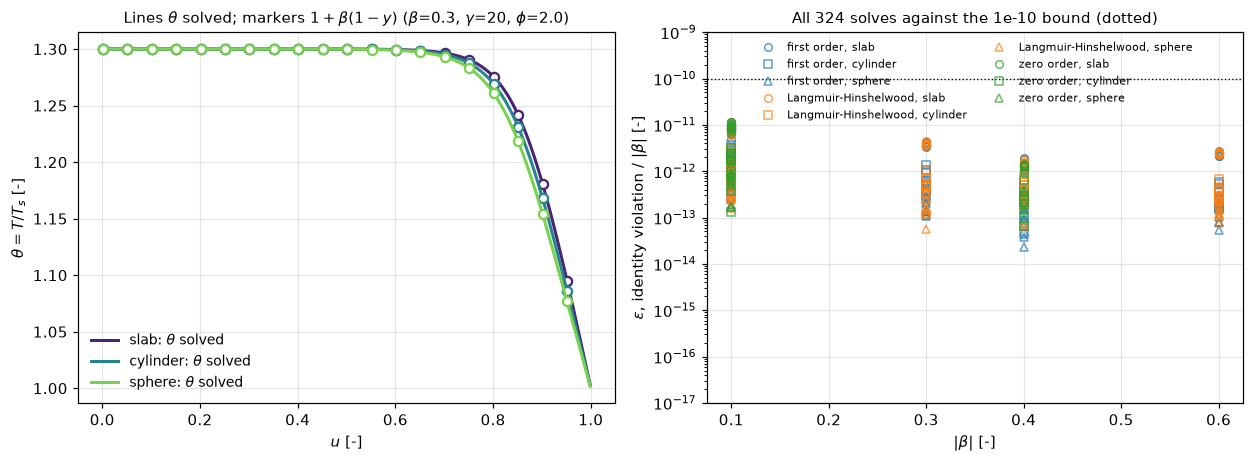

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
BETA_D, GAMMA_D, PHI_D = 0.3, 20.0, 2.0
for k, geom in enumerate(NU):
    pel = TwoFieldPellet(geom, 400)
    v, _ = pel.solve(PHI_D, BETA_D, FirstOrder(GAMMA_D))
    c_ = plt.cm.viridis(0.1 + 0.35 * k)
    axes[0].plot(pel.x_c, v[:, 1], color=c_, lw=2, label=rf"{geom}: $\theta$ solved")
    axes[0].plot(pel.x_c[::20], 1 + BETA_D * (1 - v[::20, 0]), "o", color=c_,
                 ms=6, mfc="white", mew=1.5, label="_nolegend_")
axes[0].set_xlabel("$u$ [-]")
axes[0].set_ylabel(r"$\theta = T/T_s$ [-]")
axes[0].set_title(rf"Lines $\theta$ solved; markers $1+\beta(1-y)$"
                  rf" ($\beta$={BETA_D}, $\gamma$={GAMMA_D:.0f}, $\phi$={PHI_D})", fontsize=10)
axes[0].legend(frameon=False, fontsize=9)
COLK = {"first order": "tab:blue", "Langmuir-Hinshelwood": "tab:orange", "zero order": "tab:green"}
MRK = {"slab": "o", "cylinder": "s", "sphere": "^"}
for kin in COLK:
    for geom in MRK:
        sel = [r for r in ROWS if r["kin"] == kin and r["geom"] == geom]
        axes[1].semilogy([abs(r["beta"]) for r in sel], [max(r["eps"], 1e-17) for r in sel],
                         MRK[geom], color=COLK[kin], ms=5, alpha=0.7, mfc="none",
                         label=f"{kin}, {geom}")
axes[1].axhline(1e-10, color="k", ls=":", lw=0.9)
axes[1].set_xlabel(r"$|\beta|$ [-]")
axes[1].set_ylabel(r"$\varepsilon$, identity violation / $|\beta|$ [-]")
axes[1].set_ylim(1e-17, 1e-9)
axes[1].set_title(f"All {len(ROWS)} solves against the 1e-10 bound (dotted)", fontsize=10)
axes[1].legend(frameon=False, fontsize=7, ncol=2, loc="upper center")
fig.tight_layout(); plt.show()

### 5. Breaking it on purpose: what the violation can and cannot catch

An agreement number is worth exactly what it would cost to break. One case of
the sweep (the sphere at $\phi = 2$, $\beta = 0.3$, $\gamma = 20$) is solved
again with **one implementation error injected at a time**, and three numbers
are measured each time: $\varepsilon$, the effectiveness factor $\eta$, and
the backward error.

The first four rows inject **inconsistencies between the two balances**: a
sign, a scale, a boundary condition type, a rate evaluated at the wrong state.
$\varepsilon$ moves by more than ten orders of magnitude, and *linearly* in the
defect: with the heat source scaled by $1+\delta$, the combination
$\theta + (1+\delta)\beta y$ is the harmonic one, so
$\varepsilon = \delta\,(1 - y_{\min})$ exactly.

The last three rows change things that are wrong in the ordinary, expensive
ways: a Newton solve stopped after one iteration, the wrong geometry index, a
grid far too coarse to resolve anything. **$\varepsilon$ does not move for any
of them**, because $w$ is a closed linear subsystem of the discrete
equations, satisfied by every full Newton step on any grid and for any
$\nu$. They are caught by $\eta$ and by the backward error instead. One
consequence is that the *severity* of the sweep adds no evidential weight to
$\varepsilon$: one solve would have given the same number.

In [10]:
DPHI, DBETA, DGAMMA, DN = 2.0, 0.3, 20.0, 200       # the defect case, one of the sweep
D_RATE = FirstOrder(DGAMMA)
DEFECTS = [("heat source with -beta (heat_factor = -1)", {}, {"heat_factor": -1.0}),
           ("heat source 1 % too large (heat_factor = 1.01)", {}, {"heat_factor": 1.01}),
           ("film on theta only, Bi_h = 50 (y Dirichlet)", {"bi_h": 50.0}, {}),
           ("rate at theta = 1 in the energy equation", {}, {"energy_rate_isothermal": True}),
           ("sphere assembled with nu = 0", {"nu": 0}, {}),
           ("3 cells", {"n": 3}, {}),
           ("newton stopped after 1 iteration", {}, None)]


def defect_case(pellet_kw, solve_kw):
    """eps, eta, backward error and y_min of the defect case with one defect."""
    pel = TwoFieldPellet("sphere", **{"n": DN, **pellet_kw})
    if solve_kw is None:
        v, solve_kw = pel.newton_iterate(DPHI, DBETA, D_RATE, maxfev=1), {}
    else:
        v, _ = pel.solve(DPHI, DBETA, D_RATE, **solve_kw)
    return (violation(v, DBETA), pel.eta(v, DPHI),
            pel.backward_error(v, DPHI, DBETA, D_RATE, **solve_kw), float(v[:, 0].min()))


def show(x):
    """A table cell: round-off-sized values as this run's value."""
    return f"{ro(x):>16}" if abs(x) < 1e-9 else f"{x:16.4g}"


BASE = defect_case({}, {})
claims.bound("baseline_identity_violation", BASE[0], max=1e-10, basis="identity",
             note="round-off, as in the sweep")
claims.value("baseline_eta", BASE[1], rtol=1e-6)
claims.bound("baseline_backward_error", BASE[2], max=1e-12, basis="tolerance",
             note="newton tol 1e-12 with stagnation=True")
print(f"{'injected defect':<48} {'eps':>16} {'eta':>16} {'backward error':>16}")
print(f"{'none':<48} {show(BASE[0])} {show(BASE[1])} {show(BASE[2])}")
DEF = {}
for label, pkw, skw in DEFECTS:
    DEF[label] = defect_case(pkw, skw)
    e, et, be, _ = DEF[label]
    print(f"{label:<48} {show(e)} {show(et)} {show(be)}")
    brk(label, "baseline_identity_violation", e)
    brk(label, "baseline_eta", et)
    brk(label, "baseline_backward_error", be)

_e, _, _, _ymin = DEF["heat source 1 % too large (heat_factor = 1.01)"]
claims.bound("heat_scale_response", abs(_e / (0.01 * (1.0 - _ymin)) - 1.0), max=1e-9,
             basis="identity", note="eps = delta (1 - y_min) for a heat source scaled by 1 + delta")
_e2, _, _, _ymin2 = defect_case({"bi_h": 50.0}, {"heat_factor": 1.01})
brk("film on theta only, Bi_h = 50, under the 1 % heat-source probe", "heat_scale_response",
    abs(_e2 / (0.01 * (1.0 - _ymin2)) - 1.0))
BLIND = ("sphere assembled with nu = 0", "3 cells", "newton stopped after 1 iteration")
claims.bound("blind_rows_max_identity_violation", max(DEF[b][0] for b in BLIND), max=1e-10,
             basis="identity", note="the three defects eps is blind to: round-off, as in the sweep")
brk("heat source 1 % too large (the defect eps is not blind to)",
    "blind_rows_max_identity_violation", DEF["heat source 1 % too large (heat_factor = 1.01)"][0])
print(f"\nthe three defects eps is blind to (nu = 0, 3 cells, one Newton step): worst eps below "
      f"1e-10 {ro(claims['blind_rows_max_identity_violation'])}")
print(f"heat source 1 % too large: eps / (0.01 (1 - y_min)) - 1 is below 1e-9 "
      f"{ro(claims['heat_scale_response'])}")
print(f"the iterate after one Newton step has y = {TwoFieldPellet('sphere', DN).newton_iterate(DPHI, DBETA, D_RATE, 1)[0, 0]:.2f}"
      " at the centre, more reactant than at the surface, and eps is still at round-off.")

# the sweep under the same kinds of defect
_r = sweep(heat_factor=1.01)
for name, val in zip(("sweep_worst_identity_violation", "sweep_worst_backward_error",
                      "sweep_largest_eta"), sweep_metrics(_r)):
    brk("heat source 1 % too large in every sweep case", name, val)
_r = sweep_iterates(1)
for name, val in zip(("sweep_worst_identity_violation", "sweep_worst_backward_error",
                      "sweep_largest_eta"), sweep_metrics(_r)):
    brk("newton stopped after 1 iteration in every sweep case", name, val)

injected defect                                               eps              eta   backward error
none                                               (here 1.4e-13)            3.856   (here 7.2e-17)
heat source with -beta (heat_factor = -1)                  0.4233           0.5181   (here 6.8e-17)
heat source 1 % too large (heat_factor = 1.01)               0.01            3.918   (here 8.8e-17)
film on theta only, Bi_h = 50 (y Dirichlet)                0.1554            5.826   (here 8.2e-17)
rate at theta = 1 in the energy equation                    0.544            1.306   (here 9.5e-17)
sphere assembled with nu = 0                       (here 4.1e-12)            5.009   (here 7.8e-17)
3 cells                                            (here 1.7e-15)            5.276   (here 2.8e-17)
newton stopped after 1 iteration                   (here 1.4e-13)         -0.01428        2.696e-05

the three defects eps is blind to (nu = 0, 3 cells, one Newton step): worst eps below 1e-10 (here 4

So $\varepsilon$ tests one thing: that the two balances see the same rate with
the same sign and scale, and that the two fields carry the same kind of
boundary condition. Convergence is established separately, by the backward
error; the discretisation, by the comparisons in sections 6 and 7. One
qualification, from the sweep rows of the break table: where the bound on
$\theta$ shortens the first Newton step, that step is no longer a Newton step
for the linear subsystem, and the iterate after it does move $\varepsilon$.
That is a property of the shortened step, not a convergence check.

### 6. A second discretisation: what it settles and what it does not

The same problem is solved again with `scipy.solve_bvp`: collocation on an
adaptive mesh, a different method, a different solver, and no pymrm anywhere.
The domain starts at $u_0 = 10^{-4}$ with the regular-singular series condition
$y'(u_0) = \phi^2\mathcal{R}\,u_0/(\nu+1)$, and $\beta$ is ramped inside this
solver; the pymrm solution is never used as a starting guess.

**This does not make the identity check independent.** `solve_bvp` puts the
same mesh and the same collocation nodes under every component, and in its
first-order system $w$ and $w'$ again form a closed linear pair with the rate
cancelled, so the invariant is inherited for the same structural reason.

**What the collocation run does contribute is the profiles.** Comparing $y(u)$
between the two solvers is a test of the pymrm discretisation that can fail. It
is made on a grid ladder, against a reference whose own tolerance and start
point are refined too.

In [11]:
PROFILE_CASES = (("slab", 1.0, 0.3, 20.0), ("cylinder", 2.0, -0.3, 20.0),
                 ("sphere", 0.5, 0.6, 20.0))            # (geometry, phi, beta, gamma)
LADDER = (100, 200, 400, 800)
U_FINE = np.linspace(1e-3, 1.0, 4001)
COLL = {c: collocation(NU[c[0]], *c[1:]) for c in PROFILE_CASES}
assert all(s.status == 0 for s in COLL.values()), "a collocation reference did not converge"


def profile_gaps(n, nu=None, at="centres"):
    """max |y_pymrm - y_collocation| per case on n cells; at="faces" reads the
    collocation solution at the cells' outer faces instead of their centres (a defect)."""
    out = []
    for c in PROFILE_CASES:
        g, phi, beta, gamma = c
        pel = TwoFieldPellet(g, n, nu=nu)
        v, _ = pel.solve(phi, beta, FirstOrder(gamma))
        x = pel.x_c if at == "centres" else pel.x_f[1:]
        out.append(float(np.max(np.abs(v[:, 0] - COLL[c].sol(x)[0]))))
    return np.array(out)


def reference_change(u0=1e-4):
    """Largest change of the collocation y(u) with its tolerance (1e-8 to 1e-9) and
    its start point (u0 to u0/100), over the cases."""
    out = 0.0
    for c in PROFILE_CASES:
        g, phi, beta, gamma = c
        base = collocation(NU[g], phi, beta, gamma, u0=u0).sol(U_FINE)[0]
        for kw in ({"tol": 1e-9, "u0": u0}, {"u0": u0 / 100}):
            alt = collocation(NU[g], phi, beta, gamma, **kw).sol(U_FINE)[0]
            out = max(out, float(np.max(np.abs(alt - base))))
    return out


def collocation_eps(heat_factor=1.0):
    out = 0.0
    for c in PROFILE_CASES:
        g, phi, beta, gamma = c
        s = COLL[c] if heat_factor == 1.0 else collocation(NU[g], phi, beta, gamma,
                                                           heat_factor=heat_factor)
        yy, tt = s.sol(U_FINE)[0], s.sol(U_FINE)[2]
        out = max(out, float(np.max(np.abs((tt - 1.0) - beta * (1.0 - yy))) / abs(beta)))
    return out


GAPS = {n: profile_gaps(n) for n in LADDER}
P_ORD = np.log2(GAPS[200] / GAPS[400])
print(f"{'case':>28} " + " ".join(f"{'n = %d' % n:>16}" for n in LADDER) + "   order 200->400")
for i, (g, phi, beta, gamma) in enumerate(PROFILE_CASES):
    lbl = f"{g} phi={phi:g} beta={beta:+.1f}"
    print(f"{lbl:>28} " + " ".join(ladder_cell(GAPS[n][i], n) for n in LADDER)
          + f"   {P_ORD[i]:.3f}")
REF_CHANGE = reference_change()
P_GUARD = float(np.min(GAPS[400] / (400**2 * EPS)))
claims.value("pymrm_vs_collocation_profile_n800", GAPS[800].max(), rtol=1e-3)
claims.bound("collocation_profile_order_min", P_ORD.min(), min=1.9, max=2.1, basis="theory",
             note="second-order finite volume, orders from 200 and 400 cells")
claims.bound("collocation_profile_order_max", P_ORD.max(), min=1.9, max=2.1, basis="theory",
             note="second-order finite volume, orders from 200 and 400 cells")
claims.bound("collocation_profile_over_roundoff", P_GUARD, min=1e3, basis="theory",
             note="gap on 400 cells over n^2 eps, the operator's condition number times eps")
claims.bound("collocation_reference_change", REF_CHANGE, max=1e-10, basis="chosen",
             note="the reference must move far less than the n = 800 gap it judges")
claims.bound("collocation_worst_identity_violation", collocation_eps(), max=1e-10,
             basis="identity", note="inherited by the collocation equations")
print(f"\nreference change with its tolerance and start point: below 1e-10 {ro(REF_CHANGE)}")
print(f"gap on 400 cells over its round-off estimate n^2 eps: at least 1e3 {ro(P_GUARD)}")
print(f"identity violation of the collocation solutions: below 1e-10 {ro(claims['collocation_worst_identity_violation'])}")

                        case          n = 100          n = 200          n = 400          n = 800   order 200->400
        slab phi=1 beta=+0.3        6.346e-05        1.594e-05        3.997e-06        1.000e-06   1.996
    cylinder phi=2 beta=-0.3        1.068e-05        2.734e-06        6.918e-07        1.740e-07   1.983
    sphere phi=0.5 beta=+0.6        4.687e-06        1.174e-06        2.939e-07   (here 7.4e-08)   1.998



reference change with its tolerance and start point: below 1e-10 (here 2.1e-12)
gap on 400 cells over its round-off estimate n^2 eps: at least 1e3 (here 8.3e+03)
identity violation of the collocation solutions: below 1e-10 (here 1.3e-15)


In [12]:
display(Markdown(
    f"pymrm approaches the collocation profiles at second order (orders "
    f"{P_ORD.min():.2f} to {P_ORD.max():.2f}) and agrees to "
    f"{claims['pymrm_vs_collocation_profile_n800']:.1e} at 800 cells. The reference "
    "itself moves by less than 1e-10 when its tolerance or its start point is refined."))

pymrm approaches the collocation profiles at second order (orders 1.98 to 2.00) and agrees to 1.0e-06 at 800 cells. The reference itself moves by less than 1e-10 when its tolerance or its start point is refined.

### 7. Cross-check against the published `B1.1`/`B1.5` page

The Weisz-Hicks page solves a **single** equation, obtained by substituting the
Prater relation into the species balance:

$$\nabla^2 y = \phi^2\,y\,\exp\!\left[\frac{\gamma\beta(1-y)}{1+\beta(1-y)}\right].$$

If the relation is exact, that reduced equation and this page's two-field
system must have the *same* solution, not merely a similar one. Three
comparisons, at the $\beta = 0.6$, $\gamma = 20$ that `B1.1` uses for its
multiplicity result, and they are **not of equal weight**:

1. $\beta$ **recovered** from the two-field solution as $(\theta-1)/(1-y)$,
   which should be the constant $0.6$ everywhere. This is the section 4
   identity divided by $(1-y)$; its content is that this page and `B1.1`
   attach the same value to the same symbol. A **convention check**.
2. The reduced equation solved on the same grid with the same operators. Given
   the discrete identity and the algebraic identity
   $\gamma(1-1/\theta) \equiv \gamma\beta(1-y)/[1+\beta(1-y)]$, the two-field
   $y$ is a root of the reduced discrete system, so this agreement is
   guaranteed. It tests that the two pages' $\gamma$ and $\beta$ enter the
   exponent the same way: an **implementation-consistency check**.
3. The **shooting** reference of `B1.1`, which integrates the reduced sphere
   equation outward from the centre and discretises nothing. With
   $s = \phi u$ the equation does not contain $\phi$, so the radius at which
   $y$ reaches 1 is $\phi$; the centre value is root-found so that it is the
   $\phi$ of the pymrm solve, on the branch through the pymrm centre value.
   This comparison can fail, and it tests the pymrm discretisation.

In [13]:
BETA_X, GAMMA_X, N_X = 0.6, 20.0, 400
PHIS_X = (0.2, 0.4, 0.8, 2.0)
B11 = load_claims("B1.1-thiele-weisz-hicks")


def cross_page(heat_factor=1.0, reduced_beta_factor=1.0):
    """Per geometry and phi: |beta recovered - 0.6|, max |y_two_field - y_reduced|, both etas."""
    out = []
    for geom in NU:
        for phi in PHIS_X:
            pel = TwoFieldPellet(geom, N_X)
            v, _ = pel.solve(phi, BETA_X, FirstOrder(GAMMA_X), heat_factor=heat_factor)
            red = ReducedPellet(geom, N_X)
            y_red = red.solve(phi, BETA_X * reduced_beta_factor, GAMMA_X, v[:, :1])
            m = (1.0 - v[:, 0]) > 1e-10
            be = float(np.max(np.abs((v[m, 1] - 1.0) / (1.0 - v[m, 0]) - BETA_X)))
            out.append((geom, phi, be, float(np.max(np.abs(v[:, 0] - y_red[:, 0]))),
                        pel.eta(v, phi)))
    return out


XP = cross_page()
print(f"{'geometry':>10} {'phi':>5} {'|beta - 0.6|':>18} {'max|y2 - yred|':>18} {'eta':>10}")
for geom, phi, be, dy, eta in XP:
    print(f"{geom:>10} {phi:5.2f} {ro(be):>18} {ro(dy):>18} {eta:10.5f}")
claims.bound("beta_recovered_vs_0p6", max(r[2] for r in XP), max=1e-8, basis="identity",
             note="round-off divided by 1 - y, which is small near the surface")
claims.bound("two_field_vs_reduced_max_dy", max(r[3] for r in XP), max=1e-10, basis="identity",
             note="the two-field y is a root of the reduced discrete system")
brk("heat source 1 % too large in the two-field solves", "beta_recovered_vs_0p6",
    max(r[2] for r in cross_page(heat_factor=1.01)))
brk("reduced equation solved with beta 1 % too large", "two_field_vs_reduced_max_dy",
    max(r[3] for r in cross_page(reduced_beta_factor=1.01)))
print(f"\nbeta recovered: 0.6 to below 1e-8; two-field against reduced: below 1e-10 in y")
print(f"B1.1 places the sphere's multiplicity window at phi from {B11['phi_fold_lower']:.4f} to "
      f"{B11['phi_fold_upper']:.4f} (its committed claims); phi = 0.4 lies inside it, so")
print("several steady states exist there; the next cell says which one the solve reaches.")

  geometry   phi       |beta - 0.6|     max|y2 - yred|        eta
      slab  0.20     (here 3.0e-10)     (here 4.7e-12)    1.20089
      slab  0.40     (here 6.4e-12)     (here 5.3e-12)   26.27869
      slab  0.80     (here 7.5e-12)     (here 3.4e-12)   13.13936
      slab  2.00     (here 7.6e-12)     (here 1.2e-12)    5.25579
  cylinder  0.20     (here 6.3e-11)     (here 2.2e-13)    1.06167
  cylinder  0.40     (here 6.2e-12)     (here 9.9e-13)    1.44169
  cylinder  0.80     (here 3.3e-13)     (here 2.6e-13)   23.65614
  cylinder  2.00     (here 5.6e-13)     (here 2.8e-14)   10.10582
    sphere  0.20     (here 4.8e-11)     (here 3.4e-13)    1.03125
    sphere  0.40     (here 1.3e-11)     (here 5.1e-13)    1.15883
    sphere  0.80     (here 3.0e-13)     (here 2.1e-13)   31.56757
    sphere  2.00     (here 3.2e-13)     (here 7.5e-14)   14.55224



beta recovered: 0.6 to below 1e-8; two-field against reduced: below 1e-10 in y
B1.1 places the sphere's multiplicity window at phi from 0.2973 to 0.5719 (its committed claims); phi = 0.4 lies inside it, so
several steady states exist there; the next cell says which one the solve reaches.


**Which steady state.** Where several steady states exist, `pseudo_transient`
from the surface state reaches the least-ignited one, the state a start-up from
surface conditions reaches. Three checks. (a) A Newton solve seeded on the hot
state ($y = 10^{-3}$, $\theta = 1 + \beta(1-y)$) is run for every sweep case
with $\beta > 0$; where it converges to a different state, that case has
several steady states, and the page's state is compared with it. (b) At
$\phi = 0.4$ (the sphere, $\beta = 0.6$, $\gamma = 20$, inside the window of
`B1.1`) the upper state is found the same way. (c) The page's state at
$\phi = 0.4$ is compared with a resolved $Le = 1$ start-up, `solve_ivp` (BDF,
error-controlled) integrating the semi-discrete system from the surface state
to $\tau = 10^3$.

In [14]:
N_POS = [c for c in CASES if c[3] > 0]
HOT_Y = 1e-3


def seed_state(pel, beta, y0):
    """A uniform state: reactant y0 and the temperature the identity gives with it."""
    y = np.full(pel.n, y0)
    return np.stack([y, 1.0 + beta * (1.0 - y)], axis=1)


def seeded_root(pel, phi, beta, rate, y0):
    """Newton from the uniform state seed_state(y0); None where it does not converge."""
    r = newton(lambda x: pel.residual(x, phi, beta, rate), seed_state(pel, beta, y0),
               tol=1e-12, stagnation=True, maxfev=50, bounds=pel.bounds)
    return r.x.reshape(pel.shape) if r.success else None


SOLVED = {}


def several_states(y0=HOT_Y):
    """Per beta > 0 sweep case: the largest difference between the page's state and the
    root found from the seed y0 (0 where there is none, or none with y >= 0), and
    whether the page's state is the less ignited of the two."""
    diffs, lowest = [], 0
    for kin, geom, gamma, beta, phi in N_POS:
        pel, rate = TwoFieldPellet(geom, N_SWEEP), KIN[kin](gamma)
        if (kin, geom, gamma, beta, phi) not in SOLVED:
            SOLVED[(kin, geom, gamma, beta, phi)] = pel.solve(phi, beta, rate)[0]
        v = SOLVED[(kin, geom, gamma, beta, phi)]
        w = seeded_root(pel, phi, beta, rate, y0)
        if w is None or w[:, 0].min() < -1e-6:     # no root, or an unphysical one
            diffs.append(0.0)
            continue
        diffs.append(float(np.max(np.abs(w - v))))
        lowest += bool(diffs[-1] > 1e-6 and pel.eta(v, phi) < pel.eta(w, phi))
    return np.array(diffs), lowest


_d, _low = several_states()
N_MULTI = claims.count("sweep_cases_several_states", _d, 1e-6, min_margin=0.5,
                       note="beta > 0 cases whose root from the hot seed differs from the page's")
claims.exact("sweep_several_states_page_lowest", _low,
             note="of those cases, the ones in which the page's state has the smaller eta")
print(f"{N_MULTI} of the {len(N_POS)} sweep cases with beta > 0 have a second steady state; "
      f"the page's solve is on the less ignited one in {_low} of them")
_d1, _low1 = several_states(y0=1.0)
brk("second state sought from the surface state instead of the hot state",
    "sweep_cases_several_states", int(np.sum(_d1 > 1e-6)))
brk("second state sought from the surface state instead of the hot state",
    "sweep_several_states_page_lowest", _low1)

PEL4, RATE4 = TwoFieldPellet("sphere", N_X), FirstOrder(GAMMA_X)
V4 = PEL4.solve(0.4, BETA_X, RATE4)[0]
W4 = seeded_root(PEL4, 0.4, BETA_X, RATE4, HOT_Y)


def startup(w0, le=1.0):
    """The state at tau = 1e3 of the semi-discrete start-up from w0 (solve_ivp, BDF)."""
    sol = solve_ivp(lambda t, w: _rhs(PEL4, w, 0.4, BETA_X, RATE4, le, 1.0)[0], (0.0, 1e3),
                    w0.ravel(), method="BDF", rtol=1e-8, atol=1e-11,
                    jac=lambda t, w: _rhs(PEL4, w, 0.4, BETA_X, RATE4, le, 1.0)[1])
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y[:, -1].reshape(PEL4.shape)


S4 = startup(np.ones(PEL4.shape))
claims.value("phi04_eta_page", PEL4.eta(V4, 0.4), rtol=1e-3)
claims.value("phi04_eta_upper", PEL4.eta(W4, 0.4), rtol=1e-3)
claims.bound("phi04_state_vs_startup", float(np.max(np.abs(S4 - V4))), max=1e-8,
             basis="tolerance", note="solve_ivp BDF rtol 1e-8, atol 1e-11, at tau = 1e3")
brk("page state replaced by the root found from the hot seed", "phi04_eta_page",
    PEL4.eta(W4, 0.4))
brk("upper state sought from the surface state with the page's solve", "phi04_eta_upper",
    PEL4.eta(V4, 0.4))
brk("start-up seeded on the upper state", "phi04_state_vs_startup",
    float(np.max(np.abs(startup(W4) - V4))))
print(f"phi = 0.4, sphere, beta = 0.6, gamma = 20: the solve reaches eta = "
      f"{claims['phi04_eta_page']:.3f}, the state a start-up from the surface state reaches "
      f"(difference below 1e-8 {ro(claims['phi04_state_vs_startup'])}); the upper steady "
      f"state there has eta = {claims['phi04_eta_upper']:.1f}.")

27 of the 180 sweep cases with beta > 0 have a second steady state; the page's solve is on the less ignited one in 27 of them


phi = 0.4, sphere, beta = 0.6, gamma = 20: the solve reaches eta = 1.159, the state a start-up from the surface state reaches (difference below 1e-8 (here 4.8e-13)); the upper steady state there has eta = 44.5.


In [15]:
PHIS_S = (0.2, 0.4, 0.8)
LADDER_S = (100, 200, 400, 800)


def shoot_errs(n, compare="phi", read="face", rtol=1e-11):
    """Relative eta error against the shooting reference per phi, sphere, n cells.
    compare="centre" reads the reference at the pymrm first-cell value instead of
    root-finding it at the same phi (a defect)."""
    out = []
    for phi in PHIS_S:
        pel = TwoFieldPellet("sphere", n)
        v, _ = pel.solve(phi, BETA_X, FirstOrder(GAMMA_X))
        if compare == "phi":
            ref = shooting_at_phi(BETA_X, GAMMA_X, phi, float(v[0, 0]), rtol=rtol)[0]
        else:
            ref = shooting(BETA_X, GAMMA_X, float(v[0, 0]), rtol=rtol)[1]
        out.append(abs(pel.eta(v, phi, read=read) / ref - 1.0))
    return np.array(out)


SH = {n: shoot_errs(n) for n in LADDER_S}
S_ORD = np.log2(SH[200] / SH[400])
print(f"{'phi':>5} " + " ".join(f"{'n = %d' % n:>16}" for n in LADDER_S) + "   order 200->400")
for i, phi in enumerate(PHIS_S):
    print(f"{phi:5.2f} " + " ".join(ladder_cell(SH[n][i], n) for n in LADDER_S)
          + f"   {S_ORD[i]:.3f}")
S_GUARD = float(np.min(SH[400] / (400**2 * EPS)))


def shooting_tol_gap(rtol=1e-11):
    """Largest relative change of the reference eta from rtol to rtol/10."""
    out = 0.0
    for phi in PHIS_S:
        pel = TwoFieldPellet("sphere", 800)
        v, _ = pel.solve(phi, BETA_X, FirstOrder(GAMMA_X))
        a = shooting_at_phi(BETA_X, GAMMA_X, phi, float(v[0, 0]), rtol=rtol)[0]
        b = shooting_at_phi(BETA_X, GAMMA_X, phi, float(v[0, 0]), rtol=rtol / 10)[0]
        out = max(out, abs(a / b - 1.0))
    return out


claims.value("vs_shooting_reference_n800", SH[800].max(), rtol=1e-3)
claims.bound("shooting_order_min", S_ORD.min(), min=1.9, max=2.1, basis="theory",
             note="second-order finite volume, orders from 200 and 400 cells")
claims.bound("shooting_order_max", S_ORD.max(), min=1.9, max=2.1, basis="theory",
             note="second-order finite volume, orders from 200 and 400 cells")
claims.bound("shooting_over_roundoff", S_GUARD, min=1e3, basis="theory",
             note="error on 400 cells over n^2 eps")
claims.bound("shooting_reference_tol_change", shooting_tol_gap(), max=1e-9, basis="tolerance",
             note="solve_ivp rtol 1e-11 against 1e-12")
display(Markdown(
    f"pymrm's $\\eta$ agrees with the shooting reference at the same $\\phi$ to "
    f"{claims['vs_shooting_reference_n800']:.1e} at 800 cells, converging at orders "
    f"{S_ORD.min():.3f} to {S_ORD.max():.3f}; the reference moves by less than 1e-9 "
    "when its tolerance is cut tenfold. Read instead at the pymrm *first-cell* value, "
    "which sits half a cell from the centre, the same comparison gives "
    f"{shoot_errs(800, compare='centre').max():.1e} on the ignited state ($\\phi = 0.8$, "
    "a nearly depleted centre): there $\\eta$ is so sensitive to the centre value that "
    "the half-cell offset, not the error in $\\eta$, sets the number."))

  phi          n = 100          n = 200          n = 400          n = 800   order 200->400
 0.20        3.248e-06        8.122e-07        2.031e-07   (here 5.1e-08)   2.000
 0.40        1.699e-05        4.253e-06        1.064e-06        2.661e-07   1.999
 0.80        1.259e-04        3.157e-05        7.900e-06        1.976e-06   1.999


pymrm's $\eta$ agrees with the shooting reference at the same $\phi$ to 2.0e-06 at 800 cells, converging at orders 1.999 to 2.000; the reference moves by less than 1e-9 when its tolerance is cut tenfold. Read instead at the pymrm *first-cell* value, which sits half a cell from the centre, the same comparison gives 4.4e-05 on the ignited state ($\phi = 0.8$, a nearly depleted centre): there $\eta$ is so sensitive to the centre value that the half-cell offset, not the error in $\eta$, sets the number.

### 8. Where it breaks (i): a film, with unequal Biot numbers

The proof needs $\theta + \beta y$ to be constant **on the boundary**. Two
Dirichlet conditions give that for free. A film does not.

With $Bi_m = k_gL/D_e$ and $Bi_h = hL/\lambda$, the steady external balances are
$Bi_m(1-y_s)$ moles in and $Bi_h(\theta_s-1)$ units of heat out, and these must
be in the same fixed proportion as inside, so

$$\theta_s - 1 = \beta\,\frac{Bi_m}{Bi_h}\,(1-y_s).$$

The **interior** relation still holds exactly, referenced to the *surface*
values: nothing inside the pellet changed. What fails is the relation people
actually write, referenced to the *bulk*. Subtracting the two gives a closed
form for the error, and it is independent of position:

$$\underbrace{(\theta - 1)}_{\text{true}} - \underbrace{\beta(1-y)}_{\text{bulk Prater}}
\;=\; \beta\,(1-y_s)\left(\frac{Bi_m}{Bi_h} - 1\right).$$

So the relation survives **if and only if $Bi_m = Bi_h$**, that is
$h/k_g = \lambda/D_e$. Nothing makes that happen:
$Bi_m/Bi_h = (k_g/h)\,(\lambda/D_e)$ multiplies a gas-side transfer ratio by a
pellet-side transport ratio, two numbers with no reason to be reciprocal. The
last column of the table is the split it produces: how much of the total
temperature rise sits *outside* the pellet, in the film, where the internal
relation has no jurisdiction.

**How to read the agreement with the closed form.** Both steps of the derivation
(that $\theta + \beta y$ is harmonic and that the surface balances fix its
boundary value) hold for the *discrete* system as well, so the numerical match
is forced; the same match on an 8-cell grid shows it. It confirms the algebra,
not the solve. The closed form contains $y_s$, an output of the solve, so it is
a statement about the structure of the error rather than a prediction. What is
contributed here is the derivation and the magnitudes.

In [16]:
BETA_F, GAMMA_F, PHI_F, N_F = 0.05, 20.0, 3.0, 400
FILM = [(100.0, 100.0), (100.0, 30.0), (100.0, 10.0), (100.0, 3.0), (10.0, 100.0)]


def film_case(bi_m, bi_h, n=N_F, nu=None, heat_factor=1.0, ratio="m/h"):
    """y_s, theta_s, theta_max, surface- and bulk-referenced eps, the closed form
    (``ratio="h/m"`` writes it with Bi_h/Bi_m, a defect) and the external share."""
    pel = TwoFieldPellet("sphere", n, bi_m=bi_m, bi_h=bi_h, nu=nu)
    v, _ = pel.solve(PHI_F, BETA_F, FirstOrder(GAMMA_F), heat_factor=heat_factor)
    (y_s, th_s), _ = pel.surface(v)
    r = bi_m / bi_h if ratio == "m/h" else bi_h / bi_m
    pred = abs((1.0 - y_s) * (r - 1.0))
    return dict(y_s=y_s, th_s=th_s, th_max=float(v[:, 1].max()),
                eps_s=violation(v, BETA_F, y_s, th_s), eps_b=violation(v, BETA_F), pred=pred,
                share=(th_s - 1.0) / (float(v[:, 1].max()) - 1.0))


def film_metrics(**kw):
    rows = [film_case(bm, bh, **kw) for bm, bh in FILM]
    surf = max(r["eps_s"] for r in rows)
    pred = max(abs(r["eps_b"] - r["pred"]) / r["pred"] for r in rows if r["pred"] > 1e-6)
    return rows, surf, pred


FROWS, F_SURF, F_PRED = film_metrics()
print(f"{'Bi_m':>6} {'Bi_h':>6} {'y_s':>9} {'theta_s':>9} {'theta_max':>10} "
      f"{'eps surface':>18} {'eps bulk':>11} {'closed form':>12} {'ext. dT':>8}")
for (bm, bh), r in zip(FILM, FROWS):
    eb = ro(r["eps_b"]) if r["eps_b"] < 1e-9 else f"{r['eps_b']:.4e}"
    print(f"{bm:6.0f} {bh:6.0f} {r['y_s']:9.6f} {r['th_s']:9.6f} {r['th_max']:10.6f} "
          f"{ro(r['eps_s']):>18} {eb:>11} {r['pred']:12.4e} {r['share']:8.1%}")
claims.bound("film_surface_referenced_residual", F_SURF, max=1e-10, basis="identity",
             note="the interior relation referenced to the surface values")
claims.bound("film_bulk_error_vs_closed_form", F_PRED, max=1e-9, basis="identity",
             note="relative; the discrete system satisfies both steps of the derivation")
claims.value("film_bulk_eps_bim100_bih10", FROWS[2]["eps_b"], rtol=1e-4)
claims.value("film_external_share_bih3", FROWS[3]["share"], rtol=1e-4)
claims.value("film_external_share_bih10", FROWS[2]["share"], rtol=1e-4)
_coarse = [film_case(100.0, 10.0, n=n) for n in (8, 40)]
F8 = abs(_coarse[0]["eps_b"] - _coarse[0]["pred"]) / _coarse[0]["pred"]
claims.bound("film_closed_form_match_8_cells", F8, max=1e-11, basis="identity",
             note="the match does not depend on resolution")
print(f"\nsurface-referenced Prater: exact to below 1e-10 {ro(F_SURF)}")
print(f"bulk-referenced Prater against the closed form: below 1e-9 relative {ro(F_PRED)}")
print(f"the same on 8 cells, which resolve nothing at phi = 3: below 1e-11 {ro(F8)}")
print(f"theta_max on 8 cells {_coarse[0]['th_max']:.6f}, on 40 cells {_coarse[1]['th_max']:.6f}, "
      f"on {N_F} cells {FROWS[2]['th_max']:.6f}: the solve changes, the match does not.")

  Bi_m   Bi_h       y_s   theta_s  theta_max        eps surface    eps bulk  closed form  ext. dT
   100    100  0.975914  1.001204   1.043748     (here 1.6e-12) (here 1.7e-12)   0.0000e+00     2.8%
   100     30  0.974911  1.004181   1.047336     (here 5.8e-12)  5.8540e-02   5.8540e-02     8.8%
   100     10  0.971339  1.014330   1.059165     (here 7.1e-12)  2.5795e-01   2.5795e-01    24.2%
   100      3  0.109030  2.484950   2.490401     (here 9.9e-12)  2.8808e+01   2.8808e+01    99.6%
    10    100  0.808118  1.000959   1.035030     (here 6.1e-12)  1.7269e-01   1.7269e-01     2.7%

surface-referenced Prater: exact to below 1e-10 (here 9.9e-12)
bulk-referenced Prater against the closed form: below 1e-9 relative (here 3.6e-11)
the same on 8 cells, which resolve nothing at phi = 3: below 1e-11 (here 1.1e-13)
theta_max on 8 cells 1.058916, on 40 cells 1.059155, on 400 cells 1.059165: the solve changes, the match does not.


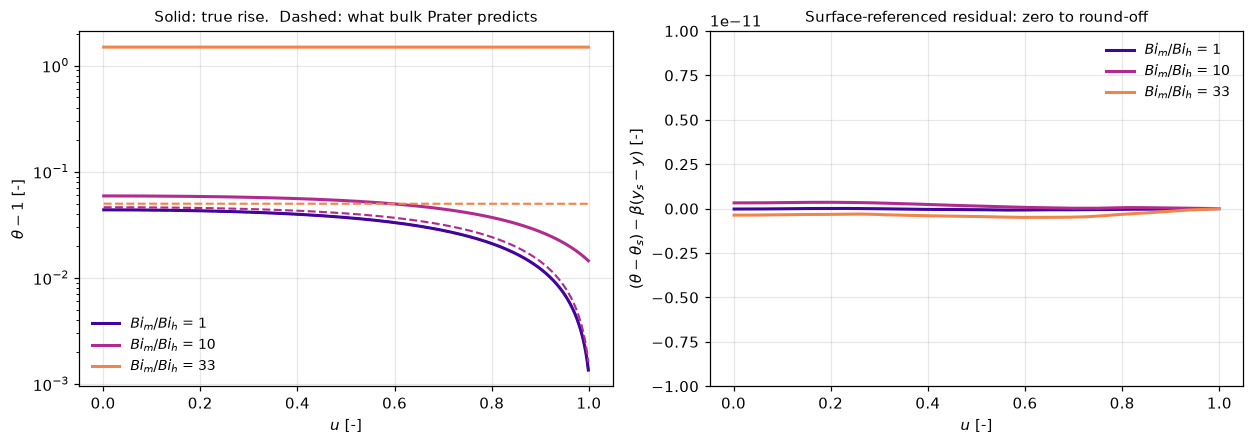

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
show_f = [(100.0, 100.0), (100.0, 10.0), (100.0, 3.0)]
cols = plt.cm.plasma(np.linspace(0.1, 0.7, len(show_f)))
for (bi_m, bi_h), c_ in zip(show_f, cols):
    pel = TwoFieldPellet("sphere", N_F, bi_m=bi_m, bi_h=bi_h)
    v, _ = pel.solve(PHI_F, BETA_F, FirstOrder(GAMMA_F))
    (y_s, th_s), _ = pel.surface(v)
    lbl = rf"$Bi_m/Bi_h$ = {bi_m / bi_h:.0f}"
    axes[0].plot(pel.x_c, v[:, 1] - 1.0, color=c_, lw=2, label=lbl)
    axes[0].plot(pel.x_c, BETA_F * (1 - v[:, 0]), color=c_, lw=1.4, ls="--")
    axes[1].plot(pel.x_c, (v[:, 1] - th_s) - BETA_F * (y_s - v[:, 0]), color=c_, lw=2, label=lbl)
axes[0].set_xlabel("$u$ [-]")
axes[0].set_ylabel(r"$\theta - 1$ [-]")
axes[0].set_yscale("log")
axes[0].set_title("Solid: true rise.  Dashed: what bulk Prater predicts", fontsize=10)
axes[0].legend(frameon=False, fontsize=9)
axes[1].set_xlabel("$u$ [-]")
axes[1].set_ylabel(r"$(\theta-\theta_s) - \beta(y_s-y)$ [-]")
axes[1].set_ylim(-1e-11, 1e-11)
axes[1].set_title("Surface-referenced residual: zero to round-off", fontsize=10)
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

### 9. Where it breaks (ii): a transient, unless Le = 1

The proof also needs steady state. With accumulation, scaling time on the
pellet's mass-diffusion time $\varepsilon_p L^2/D_e$,

$$\frac{\partial y}{\partial \tau} = \nabla^2 y - \phi^2\mathcal{R}, \qquad
\frac{\partial \theta}{\partial \tau} = Le\left[\nabla^2\theta + \beta\phi^2\mathcal{R}\right],
\qquad Le = \frac{\varepsilon_p\,\lambda}{\rho_p c_p D_e},$$

so that

$$\frac{\partial}{\partial\tau}(\theta + \beta y)
= \nabla^2(\theta + \beta y) + (Le - 1)\left[\nabla^2\theta + \beta\phi^2\mathcal{R}\right].$$

At $Le = 1$ the bracket disappears and $\theta + \beta y$ obeys a homogeneous
diffusion equation with constant data, so it stays at $1+\beta$ **at all
times**: the Prater relation is exact throughout the transient. That is a
*linear invariant* of the semi-discrete system, which a linear multistep method
with each step solved by Newton keeps to round-off, so $Le = 1$ is a control.

Away from $Le = 1$ the relation is violated during the transient and recovers
only at steady state. The runs start a sphere at bulk conditions everywhere (so
the identity holds at $\tau = 0$), $\phi = 1$, $\beta = 0.2$, $\gamma = 20$, on
100 cells, and march with variable-step BDF2 (`march` in `model.py`: steps
growing geometrically in $\tau$, one `newton` solve per step with the exact
Jacobian). The peak of $\varepsilon(\tau)$ is located on a parabola in
$\log\tau$ through the largest time level and its neighbours, and taken to its
limit in the step on a ladder of 50, 100 and 200 steps per decade.

In [18]:
BETA_T, GAMMA_T, PHI_T, N_T = 0.2, 20.0, 1.0, 100
RATE_T = FirstOrder(GAMMA_T)
WIN = {10.0: 1.0, 0.1: 5.0, 0.01: 10.0}       # Lewis number: window holding its peak
KS = (50, 100, 200)                           # steps per decade


def peak_ladder(le, n=N_T, ks=KS, order=2, heat_factor=1.0, phi=PHI_T):
    """Peak of eps(tau) per step count."""
    return [peak_of(*march(TwoFieldPellet("sphere", n), phi, BETA_T, RATE_T, le, WIN[le], k,
                           order=order, heat_factor=heat_factor)[:2])[0] for k in ks]


def richardson(p):
    """Limit in the step from the two finest rungs, second order."""
    return p[-1] + (p[-1] - p[-2]) / 3.0


def step_order(p):
    return float(np.log2(abs(p[0] - p[1]) / abs(p[1] - p[2])))


PL = {le: peak_ladder(le) for le in WIN}
TR = {le: richardson(PL[le]) for le in WIN}
T_ORD = {le: step_order(PL[le]) for le in WIN}
T_GUARD = min(abs(PL[le][-1] - PL[le][-2]) / (TR[le] * N_T**2 * EPS) for le in WIN)
IVP = {le: march_ivp(TwoFieldPellet("sphere", N_T), PHI_T, BETA_T, RATE_T, le, WIN[le])[0]
       for le in WIN}
T_IVP = max(abs(TR[le] / IVP[le] - 1.0) for le in WIN)
PL2 = {le: peak_ladder(le, n=2 * N_T, ks=(100,))[0] for le in WIN}
T_GRID = max(abs(PL2[le] / PL[le][1] - 1.0) for le in WIN)
print(f"{'Le':>6} " + " ".join(f"{'%d/decade' % k:>12}" for k in KS)
      + f" {'order':>7} {'limit':>10} {'200 cells':>11}")
for le in WIN:
    print(f"{le:6g} " + " ".join(f"{x:12.7f}" for x in PL[le])
          + f" {T_ORD[le]:7.3f} {TR[le]:10.6f} {PL2[le]:11.7f}")
claims.value("transient_worst_violation", TR[10.0], rtol=1e-3, note="Le = 10")
claims.value("transient_peak_Le0p1", TR[0.1], rtol=1e-3)
claims.value("transient_peak_Le0p01", TR[0.01], rtol=1e-3)
claims.bound("transient_step_order_min", min(T_ORD.values()), min=1.9, max=2.1, basis="theory",
             note="BDF2, orders from 50, 100 and 200 steps per decade")
claims.bound("transient_step_order_max", max(T_ORD.values()), min=1.9, max=2.1, basis="theory",
             note="BDF2, orders from 50, 100 and 200 steps per decade")
claims.bound("transient_step_over_roundoff", T_GUARD, min=1e3, basis="theory",
             note="finest step difference over n^2 eps")
claims.bound("transient_peak_vs_ivp", T_IVP, max=2e-6, basis="tolerance",
             note="BDF2 limit in the step against solve_ivp BDF at rtol 1e-9, same semi-discrete system")
claims.bound("transient_grid_change", T_GRID, max=2e-4, basis="chosen",
             note="peak on 200 cells against 100 at 100 steps per decade, relative")
print(f"\nBDF2 limit against solve_ivp (BDF, rtol 1e-9) on the same semi-discrete system: "
      f"below 2e-6 {ro(T_IVP)}")
print(f"finest step difference over its round-off estimate: at least 1e3 {ro(T_GUARD)}")

    Le    50/decade   100/decade   200/decade   order      limit   200 cells
    10    0.2520915    0.2519773    0.2519486   1.992   0.251939   0.2519601
   0.1    0.1240250    0.1239840    0.1239739   2.025   0.123971   0.1239891
  0.01    0.1459208    0.1459036    0.1458995   2.085   0.145898   0.1459074

BDF2 limit against solve_ivp (BDF, rtol 1e-9) on the same semi-discrete system: below 2e-6 (here 2.7e-07)
finest step difference over its round-off estimate: at least 1e3 (here 1.3e+07)


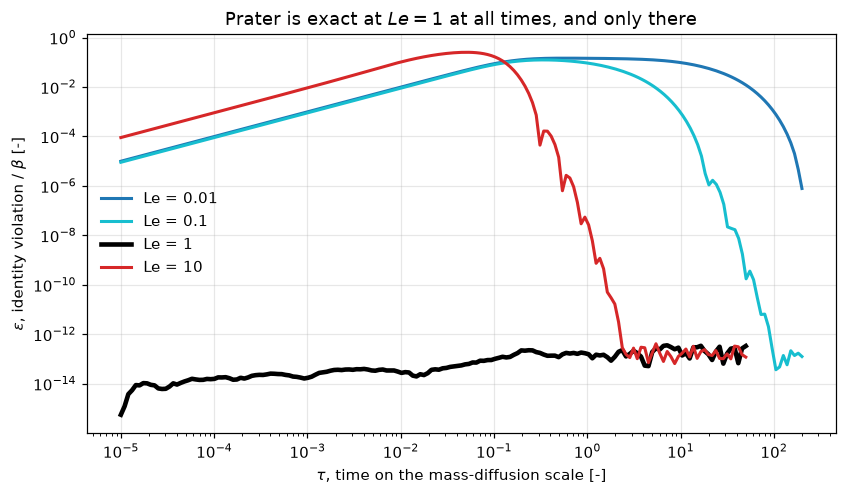

The control at $Le = 1$ stays at round-off over the whole transient (below 1e-11). Away from it the violation peaks at 0.252 of $\beta$ at $Le = 10$, 0.124 at $Le = 0.1$ and 0.146 at $Le = 0.01$, early in the start-up, and decays as the pellet approaches its steady state: below 1e-10 by the end of the window for $Le = 0.1$ and $10$, while $Le = 0.01$, the slowest, is still relaxing at $\tau = 200$. The peaks change by less than 2e-4 relative on 200 cells.

True

In [19]:
LONG = {0.01: 200.0, 0.1: 200.0, 1.0: 50.0, 10.0: 50.0}
TRACE = {le: march(TwoFieldPellet("sphere", N_T), PHI_T, BETA_T, RATE_T, le, t_end, 25)
         for le, t_end in LONG.items()}
claims.bound("transient_control_Le1", float(TRACE[1.0][1].max()), max=1e-11, basis="identity",
             note="a linear invariant of the semi-discrete system at Le = 1")
claims.bound("transient_end_violation", max(TRACE[le][1][-1] for le in (0.1, 1.0, 10.0)),
             max=1e-10, basis="chosen", note="steady state reached by the end of the window")
fig, ax = plt.subplots(figsize=(7.8, 4.6))
for le, c_ in zip(LONG, ["tab:blue", "tab:cyan", "k", "tab:red"]):
    t, d, _ = TRACE[le]
    ax.loglog(t[1:], np.maximum(d[1:], 1e-16), color=c_, lw=3 if le == 1.0 else 2,
              label=f"Le = {le:g}")
ax.set_xlabel(r"$\tau$, time on the mass-diffusion scale [-]")
ax.set_ylabel(r"$\varepsilon$, identity violation / $\beta$ [-]")
ax.set_title(r"Prater is exact at $Le=1$ at all times, and only there")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()
display(Markdown(
    f"The control at $Le = 1$ stays at round-off over the whole transient (below 1e-11). "
    f"Away from it the violation peaks at {claims['transient_worst_violation']:.3f} of "
    f"$\\beta$ at $Le = 10$, {claims['transient_peak_Le0p1']:.3f} at $Le = 0.1$ and "
    f"{claims['transient_peak_Le0p01']:.3f} at $Le = 0.01$, early in the start-up, and "
    "decays as the pellet approaches its steady state: below 1e-10 by the end of the "
    "window for $Le = 0.1$ and $10$, while $Le = 0.01$, the slowest, is still relaxing "
    "at $\\tau = 200$. The peaks change by less than 2e-4 relative on 200 cells."))
claims.says("0.252", "transient_worst_violation")
claims.says("0.124", "transient_peak_Le0p1")

## Validation

The items are **not of equal weight**. Several are identities of the discrete
system, labelled as such; none is a comparison with a measurement. This page
is **tier 6**, an identity proof with numerical confirmation, and it must not
be described as validated against experiment.

In [20]:
display(Markdown(
    "| # | check | result | can it fail? |\n|---|---|---|---|\n"
    "| 1 | eq. (7) from eqs. (4)-(5); the sign of $\\beta$ in eq. (8) | "
    f"{EQ7_OK}; reading {READING} | yes: one transcribed sign flips it |\n"
    "| 2 | the identity, symbolically, any $\\mathcal{R}$, any $\\nu$ | "
    f"{IDENTITY_OK} | yes: a sign in the species balance |\n"
    f"| 3 | $\\varepsilon$ over the {len(ROWS)} sweep cases | below 1e-10 | only by an "
    "inconsistency between the balances (section 5) |\n"
    f"| 4 | backward error over the sweep | below 1e-12 | yes: it is what says they converged |\n"
    "| 5 | pymrm against collocation profiles, 800 cells | "
    f"{claims['pymrm_vs_collocation_profile_n800']:.1e}, order {P_ORD.min():.2f} to "
    f"{P_ORD.max():.2f} | yes |\n"
    "| 6 | $\\eta$ against the shooting reference at the same $\\phi$, 800 cells | "
    f"{claims['vs_shooting_reference_n800']:.1e}, order {S_ORD.min():.2f} to "
    f"{S_ORD.max():.2f} | yes |\n"
    "| 7 | $\\beta$ recovered, and the reduced equation of `B1.1` | below 1e-8, below 1e-10 | "
    "no: guaranteed by the identity; convention checks |\n"
    "| 8 | film: surface-referenced relation, closed form | below 1e-10, below 1e-9 | "
    "no: algebraic identities of the discrete system |\n"
    "| 9 | transient control at $Le = 1$; BDF2 against `solve_ivp` | below 1e-11, below 2e-6 | "
    "the control no; the integrator comparison yes |\n"))

| # | check | result | can it fail? |
|---|---|---|---|
| 1 | eq. (7) from eqs. (4)-(5); the sign of $\beta$ in eq. (8) | True; reading + | yes: one transcribed sign flips it |
| 2 | the identity, symbolically, any $\mathcal{R}$, any $\nu$ | True | yes: a sign in the species balance |
| 3 | $\varepsilon$ over the 324 sweep cases | below 1e-10 | only by an inconsistency between the balances (section 5) |
| 4 | backward error over the sweep | below 1e-12 | yes: it is what says they converged |
| 5 | pymrm against collocation profiles, 800 cells | 1.0e-06, order 1.98 to 2.00 | yes |
| 6 | $\eta$ against the shooting reference at the same $\phi$, 800 cells | 2.0e-06, order 2.00 to 2.00 | yes |
| 7 | $\beta$ recovered, and the reduced equation of `B1.1` | below 1e-8, below 1e-10 | no: guaranteed by the identity; convention checks |
| 8 | film: surface-referenced relation, closed form | below 1e-10, below 1e-9 | no: algebraic identities of the discrete system |
| 9 | transient control at $Le = 1$; BDF2 against `solve_ivp` | below 1e-11, below 2e-6 | the control no; the integrator comparison yes |


### The break table

Each row re-runs the affected computation with one thing deliberately wrong,
injected through an argument of the code above, and hands the result to
`claims.breaks`, which records whether that claim's own check fails. The rows
of section 5 are recorded above.

In [21]:
brk("species balance with the source's sign flipped", "identity_symbolic",
    bool(rate_cancels(species_sign=+1)[0]))
brk("eq. (5) transcribed with +H as -H", "eq7_from_eqs4_5", transcription(h_sign=-1)[0])
brk("eq. (8)'s denominator transcribed as 1 - beta(1 - y)", "eq8_beta_reading",
    transcription(eq8_denominator_sign=-1)[1])
brk("dH handed over in J/mol where kJ/mol is expected", "beta_table_max_dT_K",
    max(dt for _, dt in beta_table(dh_scale=1e3)))

# collocation and profiles
brk("pymrm pellets assembled with nu = 0", "pymrm_vs_collocation_profile_n800",
    profile_gaps(800, nu=0).max())
_pf = np.log2(profile_gaps(200, at="faces") / profile_gaps(400, at="faces"))
brk("collocation read at the cells' outer faces", "collocation_profile_order_min", _pf.min())
brk("collocation read at the cells' outer faces", "collocation_profile_order_max", _pf.max())
brk("orders fitted on 3200 and 6400 cells", "collocation_profile_over_roundoff",
    float(np.min(profile_gaps(6400) / (6400**2 * EPS))))
brk("collocation started at u0 = 1e-2 instead of 1e-4", "collocation_reference_change",
    reference_change(u0=1e-2))
brk("collocation with the heat source 1 % too large", "collocation_worst_identity_violation",
    collocation_eps(heat_factor=1.01))

# shooting
brk("reference read at the pymrm first-cell value (compare='centre')",
    "vs_shooting_reference_n800", shoot_errs(800, compare="centre").max())
_sc = np.log2(shoot_errs(200, read="cell") / shoot_errs(400, read="cell"))
brk("eta from a two-point surface gradient (read='cell')", "shooting_order_min", _sc.min())
brk("eta from a two-point surface gradient (read='cell')", "shooting_order_max", _sc.max())
brk("orders fitted on 3200 and 6400 cells", "shooting_over_roundoff",
    float(np.min(shoot_errs(6400) / (6400**2 * EPS))))
brk("shooting reference at rtol 1e-7", "shooting_reference_tol_change", shooting_tol_gap(rtol=1e-7))

# film
_fr, _fs, _ = film_metrics(heat_factor=1.01)
brk("heat source 1 % too large in the film solves", "film_surface_referenced_residual", _fs)
brk("closed form written with Bi_h/Bi_m", "film_bulk_error_vs_closed_form",
    film_metrics(ratio="h/m")[2])
_c8 = film_case(100.0, 10.0, n=8, ratio="h/m")
brk("closed form written with Bi_h/Bi_m", "film_closed_form_match_8_cells",
    abs(_c8["eps_b"] - _c8["pred"]) / _c8["pred"])
brk("sphere assembled with nu = 0", "film_bulk_eps_bim100_bih10", film_case(100.0, 10.0, nu=0)["eps_b"])
brk("Bi_m and Bi_h swapped", "film_external_share_bih3", film_case(3.0, 100.0)["share"])
brk("Bi_m and Bi_h swapped", "film_external_share_bih10", film_case(10.0, 100.0)["share"])

# transient
_ph = {le: richardson(peak_ladder(le, ks=KS, phi=0.95 * PHI_T)) for le in WIN}
brk("Thiele modulus 5 % low", "transient_worst_violation", _ph[10.0])
brk("Thiele modulus 5 % low", "transient_peak_Le0p1", _ph[0.1])
brk("Thiele modulus 5 % low", "transient_peak_Le0p01", _ph[0.01])
_be = {le: peak_ladder(le, order=1) for le in WIN}
brk("backward Euler in place of BDF2 (order=1)", "transient_step_order_min",
    min(step_order(p) for p in _be.values()))
brk("backward Euler in place of BDF2 (order=1)", "transient_step_order_max",
    max(step_order(p) for p in _be.values()))
brk("backward Euler in place of BDF2 (order=1)", "transient_peak_vs_ivp",
    max(abs(richardson(_be[le]) / IVP[le] - 1.0) for le in WIN))
_rep = {le: peak_ladder(le, ks=(KS[1], KS[1])) for le in WIN}
brk("step ladder whose last rung repeats 100 per decade", "transient_step_over_roundoff",
    min(abs(_rep[le][-1] - _rep[le][-2]) / (richardson(_rep[le]) * N_T**2 * EPS) for le in WIN))
brk("grid change read on 25 and 50 cells", "transient_grid_change",
    max(abs(peak_ladder(le, n=50, ks=(100,))[0] / peak_ladder(le, n=25, ks=(100,))[0] - 1.0)
        for le in WIN))
brk("heat source 1 % too large at Le = 1", "transient_control_Le1",
    float(march(TwoFieldPellet("sphere", N_T), PHI_T, BETA_T, RATE_T, 1.0, LONG[1.0], 25,
                heat_factor=1.01)[1].max()))
brk("heat source 1 % too large at Le = 10", "transient_end_violation",
    float(march(TwoFieldPellet("sphere", N_T), PHI_T, BETA_T, RATE_T, 10.0, LONG[10.0], 25,
                heat_factor=1.01)[1][-1]))

True

In [22]:
print(f"{'injected defect':<64} {'claim':<36} {'clean':>16} {'broken':>11}  caught")
for name, metric, clean, broken, caught in BREAK:
    kind = claims.metrics[metric]["kind"]
    shown = ro(clean) if kind == "bound" else str(clean) if kind == "exact" else f"{clean:.4g}"
    b = str(broken) if kind == "exact" else (ro(broken) if abs(broken) < 1e-9 else f"{broken:.4g}")
    print(f"{name[:64]:<64} {metric[:36]:<36} {shown:>16} {b:>11}  {'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                                  claim                                           clean      broken  caught
heat source with -beta (heat_factor = -1)                        baseline_identity_violation            (here 1.4e-13)      0.4233  yes
heat source with -beta (heat_factor = -1)                        baseline_eta                                    3.856      0.5181  yes
heat source with -beta (heat_factor = -1)                        baseline_backward_error                (here 7.2e-17) (here 6.8e-17)  NO
heat source 1 % too large (heat_factor = 1.01)                   baseline_identity_violation            (here 1.4e-13)        0.01  yes
heat source 1 % too large (heat_factor = 1.01)                   baseline_eta                                    3.856       3.918  yes
heat source 1 % too large (heat_factor = 1.01)                   baseline_backward_error                (here 7.2e-17) (here 8.8e-17)  NO
film on theta only, Bi_h = 50 (y Dirichle

The rows that do **not** fail their claim are the point of section 5: the
identity violation is blind to a Newton solve stopped after one iteration, to
the wrong geometry index and to a 3-cell grid, and the backward error is blind
to every defect that still leaves a converged solve of a wrong model. Each of
those defects is caught by another claim in the same row group.

**What this page cannot conclude.** The assumption that both balances share
one reaction rate is not tested, nor are a variable $D_e$ and $\lambda$, where
only the Kirchhoff-transformed relation between the potentials survives.
Zero-order kinetics is swept at small $\phi$ only, because above a threshold a
dead core forms and no steady state exists to test. Nothing here validates the
physics against a measurement.

## What pymrm adds

**Nothing to the identity itself.** Prater's result is exact and its proof is
two lines. Reproducing it numerically confirms an implementation, not a
theorem.

What the computation adds is **the size of the error when the assumptions
fail**, which the 1958 result could only assume away:

- **A film with $Bi_m \neq Bi_h$.** The interior relation survives, referenced
  to the surface. The bulk-referenced form, the one that gets written down, is
  wrong by $\beta(1-y_s)(Bi_m/Bi_h-1)$, uniformly in position. That closed form
  is derived here, not in either source; the numerics agree with it to
  round-off because the derivation holds step for step in the discrete system,
  so what the computation supplies is the magnitude: how much of the
  temperature rise moves out of the pellet and into the film.
- **A transient with $Le \neq 1$.** The relation is a linear invariant of the
  time-dependent system exactly when $Le = 1$; the computation keeps it to
  round-off there and measures the violation elsewhere (section 9),
  peaking early in the start-up and decaying at steady state. A quasi-steady
  pellet model that carries the Prater relation into a dynamic simulation makes
  an error of this size.
- **Geometry, kinetics and boundary type as arguments.** `nu = 0, 1, 2`, a
  swapped rate function and a film on either field cover the whole sweep and
  the defect table with one class. The two-field state is one
  `BlockLayout.from_fields` layout, the coupling block is one
  `construct_coefficient_matrix` call, `pseudo_transient` reaches every case
  of the sweep from the surface state without a path in $\beta$, and the same
  operators march the transient with one `newton` solve per step.

**And the identity is a cheap unit test for any non-isothermal pellet code,
for one specific class of bug.** Solve both balances, evaluate
$(\theta-1)-\beta(1-y)$, and a number that is not at round-off means the two
balances disagree about the reaction: a wrong sign or scale on the heat source,
a rate evaluated at inconsistent states, or two fields carrying different kinds
of boundary condition. The response is exact: a heat source scaled by
$1+\delta$ gives $\varepsilon = \delta(1-y_{\min})$.

**It will not tell you anything else.** $\varepsilon$ stays at round-off for a
Newton iterate that has not converged (even one with more reactant at the
centre than at the surface), for the wrong geometry index, and for a grid three
cells wide. Those need the backward error, a comparison against an independent
method, and grid refinement, all of which are on this page because
$\varepsilon$ cannot stand in for them.

## Reuse

| Change | Where |
|---|---|
| Different geometry | `TwoFieldPellet(geom=...)`, or a callable `nu` in `construct_div` |
| Different kinetics | pass any `rate(y, theta)` returning the rate and its two partial derivatives |
| External film | `TwoFieldPellet(..., bi_m=, bi_h=)`; both Robin rows have $a = 1$ |
| Transient | `march(pellet, phi, beta, rate, le, t_end, per_decade)`; the operators are the steady ones |
| More species | widen the field axis, `BlockLayout.from_fields([...], (n,))`, temperature last |
| Reversible or multiple reactions | the identity needs **one** shared rate; with several, one relation per independent reaction extent |

**The trap this page exists to flag.** The Prater relation is usually quoted
with the bulk concentration and bulk temperature, because that is what is
measurable. That version is only correct when the surface and bulk coincide, or
when $Bi_m = Bi_h$. Referenced to the surface it is exact; referenced to the
bulk it is not, and section 8 gives the error in closed form.

**Comparing $\eta$ with a shooting reference.** Compare at the same $\phi$.
The first cell's value of a finite-volume solution is not the centre value; on
an ignited state, where the centre is nearly depleted, $\eta$ is so sensitive
to the centre value that reading the reference there measures the half-cell
offset instead of the error in $\eta$ (section 7).

**Reading Weisz and Hicks.** The scan's text layer is unusable for equations:
eq. (7) comes out as `AT = T - To = - F` and eq. (2) as `[grad ~1,~~`. Render
journal page 266 at 600 dpi and read it. The prose OCRs acceptably; the numbers
and symbols do not. The same trap is recorded for `B3.1` and in
`docs/pdf-findings.md`.

**Related pages.** [`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/), the
non-isothermal pellet this relation makes solvable, where $\beta$ is a curve
label; `B1.2` Aris generalised modulus; `B1.4` Weisz-Prater criterion (the
observable-quantity counterpart of $\beta$); `D1.4` fixed bed with resolved
pellets, where the film conditions of section 8 are supplied by the reactor;
`J4.7` immobilised enzyme particle, the same `S3` structure.

## References

Prater, C. D. (1958). *The temperature produced by heat of reaction in the
interior of porous particles.* Chemical Engineering Science **8**(3-4),
284-286. [doi:10.1016/0009-2509(58)85035-6](https://doi.org/10.1016/0009-2509(58)85035-6).
**The origin of the result; not consulted for this page**, because no copy is
available. Cited as Weisz and Hicks cite it ("[11] PRATER C. D., *Chem. Engng.
Sci.* 1958 **8** 284"), with the DOI resolved and checked against that volume
and page.

Weisz, P. B. and Hicks, J. S. (1962). *The behaviour of porous catalyst
particles in view of internal mass and heat diffusion effects.* Chemical
Engineering Science **17**(4), 265-275.
[doi:10.1016/0009-2509(62)85005-2](https://doi.org/10.1016/0009-2509(62)85005-2).
**The source actually read.** Eqs. (4), (5), (7) and (8) above are transcribed
from a 600 dpi render of journal page 266.

Damköhler, G. (1943). *Z. Phys. Chem.* **A193**, 16, cited by Weisz and Hicks
as having obtained the relation for the spherical particle.

In [23]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B1.6:
  identity_symbolic                    = True             exact  exact
  eq7_from_eqs4_5                      = True             exact  exact
  eq8_beta_reading                     = '+'              exact  exact
  beta_table_max_dT_K                  = 320              value  rtol 1e-09
  sweep_worst_identity_violation       = (here 1.2e-11)   bound  bound <= 1e-10 [identity]
  sweep_worst_backward_error           = (here 1.1e-16)   bound  bound <= 1e-12 [tolerance]
  sweep_largest_eta                    = 161.65           value  rtol 0.001
  baseline_identity_violation          = (here 1.4e-13)   bound  bound <= 1e-10 [identity]
  baseline_eta                         = 3.856            value  rtol 1e-06
  baseline_backward_error              = (here 7.2e-17)   bound  bound <= 1e-12 [tolerance]
  heat_scale_response                  = (here 3.1e-12)   bound  bound <= 1e-09 [identity]
  blind_rows_max_identity_violation    = (here 4.1e-12)   bound  bound <= 1e-10 [iden